# SVM con kernel RBF sobre características espectrales (dataset completo)

In [1]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.kernel_approximation import Nystroem
from sklearn.svm import LinearSVC, SVC
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

## Configuración

In [3]:
DATA_DIR = os.path.expanduser("~/Desktop/TFM")
IMG_DIR = os.path.expanduser("~/Desktop/TFM/images")
os.makedirs(IMG_DIR, exist_ok=True)

FEATURES_PATH = os.path.join(DATA_DIR, "caracteristicas_svm_completo.npz")  # <- mismo nombre que en el notebook 14
RESULTS_CSV = os.path.join(DATA_DIR, "resultados_svm_rbf.csv")

RANDOM_STATE = 42
DPI = 150
CLASES = ["Vigilia", "Sueño"]       # se asume 0 = Vigilia, 1 = Sueño (se comprueba abajo)
N_COMPONENTS = 1000                  # nº de épocas de referencia de Nystroem (ver nota de memoria)
N_SUB = 30000                        # tamaño del submuestreo para el SVC exacto

assert os.path.exists(FEATURES_PATH), f"No encuentro {FEATURES_PATH}"


## Carga de características y estandarización

In [4]:
d = np.load(FEATURES_PATH)
F_train, y_train = d["F_train"], d["y_train"]
F_val,   y_val   = d["F_val"],   d["y_val"]
F_test,  y_test  = d["F_test"],  d["y_test"]

print("Train:", F_train.shape, "| Val:", F_val.shape, "| Test:", F_test.shape)
for nombre, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    u, c = np.unique(y, return_counts=True)
    print(f"{nombre}: " + ", ".join(f"clase {k} = {v}" for k, v in zip(u, c)))

scaler = StandardScaler().fit(F_train)
X_train = scaler.transform(F_train)
X_val   = scaler.transform(F_val)
X_test  = scaler.transform(F_test)

Train: (205045, 30) | Val: (46265, 30) | Test: (44733, 30)
train: clase 0 = 115833, clase 1 = 89212
val: clase 0 = 25530, clase 1 = 20735
test: clase 0 = 25152, clase 1 = 19581


## Función de evaluación

In [5]:
def evaluar(modelo, X, y):
    t0 = time.time()
    puntuacion = modelo.decision_function(X)
    t_inf = time.time() - t0
    y_pred = (puntuacion > 0).astype(int)
    return {
        "acc": accuracy_score(y, y_pred),
        "f1_macro": f1_score(y, y_pred, average="macro"),
        "auc": roc_auc_score(y, puntuacion),
        "sens_vigilia": (y_pred[y == 0] == 0).mean(),
        "sens_sueno": (y_pred[y == 1] == 1).mean(),
        "t_inferencia_s": t_inf,
    }, y_pred, puntuacion

## 1. Referencia: SVM lineal (C = 0,01)

In [6]:
t0 = time.time()
svm_lineal = LinearSVC(C=0.01, dual=False, max_iter=5000, random_state=RANDOM_STATE)
svm_lineal.fit(X_train, y_train)
t_fit_lineal = time.time() - t0

met_lineal_test, _, _ = evaluar(svm_lineal, X_test, y_test)
met_lineal_test["t_ajuste_s"] = t_fit_lineal
print({k: round(v, 4) for k, v in met_lineal_test.items()})

{'acc': 0.9186, 'f1_macro': 0.9179, 'auc': 0.9752, 'sens_vigilia': np.float64(0.8964), 'sens_sueno': np.float64(0.947), 't_inferencia_s': 0.0573, 't_ajuste_s': 1.408}


## 2. Nystroem + LinearSVC: búsqueda de γ y C en validación

In [7]:
GAMMAS = [0.01, 0.033, 0.1]
CS = [0.1, 1, 10]

resultados_grid = []
for gamma in GAMMAS:
    for Cval in CS:
        t0 = time.time()
        modelo = make_pipeline(
            Nystroem(kernel="rbf", gamma=gamma, n_components=N_COMPONENTS, random_state=RANDOM_STATE),
            LinearSVC(C=Cval, dual=False, max_iter=5000, random_state=RANDOM_STATE),
        )
        modelo.fit(X_train, y_train)
        t_fit = time.time() - t0
        met, _, _ = evaluar(modelo, X_val, y_val)
        resultados_grid.append({"gamma": gamma, "C": Cval,
                                "acc_val": met["acc"], "f1_macro_val": met["f1_macro"],
                                "auc_val": met["auc"], "seg": t_fit})
        print(f"gamma={gamma:<6} C={Cval:<5} acc_val={met['acc']:.4f}  "
              f"f1_macro_val={met['f1_macro']:.4f}  ({t_fit:.1f}s)")

df_grid = pd.DataFrame(resultados_grid)
df_grid

gamma=0.01   C=0.1   acc_val=0.9302  f1_macro_val=0.9290  (33.0s)
gamma=0.01   C=1     acc_val=0.9304  f1_macro_val=0.9292  (52.8s)
gamma=0.01   C=10    acc_val=0.9286  f1_macro_val=0.9274  (77.4s)
gamma=0.033  C=0.1   acc_val=0.9292  f1_macro_val=0.9279  (33.0s)
gamma=0.033  C=1     acc_val=0.9288  f1_macro_val=0.9276  (50.5s)
gamma=0.033  C=10    acc_val=0.9282  f1_macro_val=0.9270  (84.0s)
gamma=0.1    C=0.1   acc_val=0.9230  f1_macro_val=0.9215  (38.4s)
gamma=0.1    C=1     acc_val=0.9236  f1_macro_val=0.9221  (51.5s)
gamma=0.1    C=10    acc_val=0.9231  f1_macro_val=0.9217  (92.3s)


,gamma,C,acc_val,f1_macro_val,auc_val,seg
0,0.010,0.1,0.930185,0.929039,0.983336,32.953680
1,0.010,1.0,0.930401,0.929211,0.980097,52.756136
2,0.010,10.0,0.928585,0.927380,0.975942,77.442217
3,0.033,0.1,0.929169,0.927907,0.980028,32.986976
4,0.033,1.0,0.928845,0.927603,0.976635,50.524560
5,0.033,10.0,0.928218,0.926977,0.973832,84.044548
6,0.100,0.1,0.923009,0.921499,0.974349,38.448478
7,0.100,1.0,0.923592,0.922131,0.972498,51.454088
8,0.100,10.0,0.923138,0.921686,0.971649,92.286732


Se elige la combinación con mayor F1 macro en validación.

Mejor configuración en validación: gamma = 0.01, C = 1.0


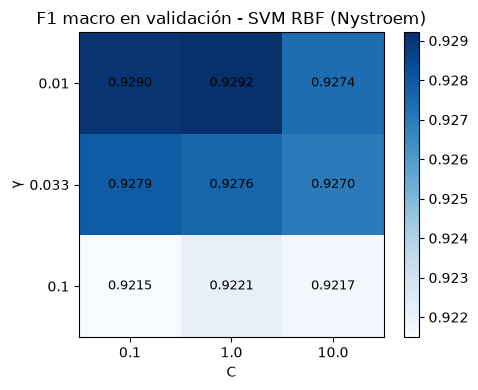

In [8]:
mejor = df_grid.sort_values(["f1_macro_val", "acc_val"], ascending=False).iloc[0]
GAMMA_BEST, C_BEST = float(mejor["gamma"]), float(mejor["C"])
print(f"Mejor configuración en validación: gamma = {GAMMA_BEST}, C = {C_BEST}")

# mapa de calor de la búsqueda
piv = df_grid.pivot(index="gamma", columns="C", values="f1_macro_val")
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(piv.values, cmap="Blues")
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels(piv.index)
ax.set_xlabel("C"); ax.set_ylabel("γ")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, f"{piv.values[i, j]:.4f}", ha="center", va="center", fontsize=9)
ax.set_title("F1 macro en validación - SVM RBF (Nystroem)")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "svm_rbf_grid_validacion.png"), dpi=DPI, bbox_inches="tight")
plt.show()

## 3. Estabilidad respecto al número de componentes

In [9]:
res_comp = []
for n in [500, 1000, 2000]:
    t0 = time.time()
    modelo = make_pipeline(
        Nystroem(kernel="rbf", gamma=GAMMA_BEST, n_components=n, random_state=RANDOM_STATE),
        LinearSVC(C=C_BEST, dual=False, max_iter=5000, random_state=RANDOM_STATE),
    )
    modelo.fit(X_train, y_train)
    met, _, _ = evaluar(modelo, X_val, y_val)
    res_comp.append({"n_components": n, "acc_val": met["acc"],
                     "f1_macro_val": met["f1_macro"], "seg": time.time() - t0})
    print(res_comp[-1])
pd.DataFrame(res_comp)

{'n_components': 500, 'acc_val': 0.9306170971576786, 'f1_macro_val': 0.9294450310966327, 'seg': 22.380624294281006}
{'n_components': 1000, 'acc_val': 0.930400951042905, 'f1_macro_val': 0.929210751183339, 'seg': 53.01619505882263}
{'n_components': 2000, 'acc_val': 0.9304225656543824, 'f1_macro_val': 0.9292282930179503, 'seg': 113.33113527297974}


,n_components,acc_val,f1_macro_val,seg
0,500,0.930617,0.929445,22.380624
1,1000,0.930401,0.929211,53.016195
2,2000,0.930423,0.929228,113.331135


## 4. Modelo final (Nystroem) y evaluación en test

In [10]:
t0 = time.time()
svm_rbf = make_pipeline(
    Nystroem(kernel="rbf", gamma=GAMMA_BEST, n_components=N_COMPONENTS, random_state=RANDOM_STATE),
    LinearSVC(C=C_BEST, dual=False, max_iter=5000, random_state=RANDOM_STATE),
)
svm_rbf.fit(X_train, y_train)
t_fit_rbf = time.time() - t0

met_rbf_test, y_pred_rbf, punt_rbf = evaluar(svm_rbf, X_test, y_test)
met_rbf_test["t_ajuste_s"] = t_fit_rbf

print(classification_report(y_test, y_pred_rbf, target_names=CLASES, digits=3))
print(f"ROC-AUC: {met_rbf_test['auc']:.3f}")
print(f"Tiempo de ajuste: {t_fit_rbf:.1f} s | inferencia sobre test: {met_rbf_test['t_inferencia_s']:.2f} s")

              precision    recall  f1-score   support

     Vigilia      0.968     0.931     0.949     25152
       Sueño      0.915     0.960     0.937     19581

    accuracy                          0.944     44733
   macro avg      0.941     0.945     0.943     44733
weighted avg      0.945     0.944     0.944     44733

ROC-AUC: 0.988
Tiempo de ajuste: 55.4 s | inferencia sobre test: 1.01 s


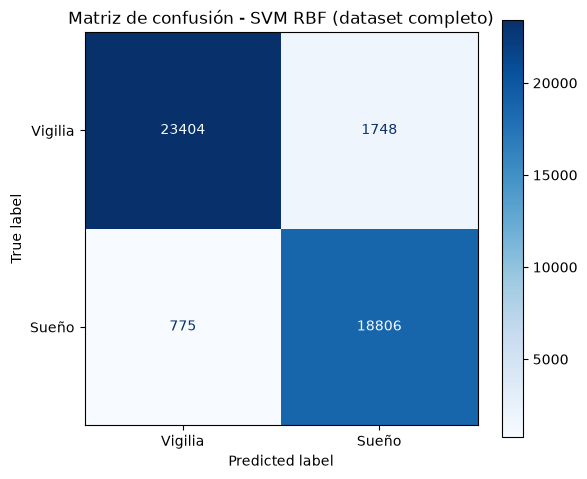

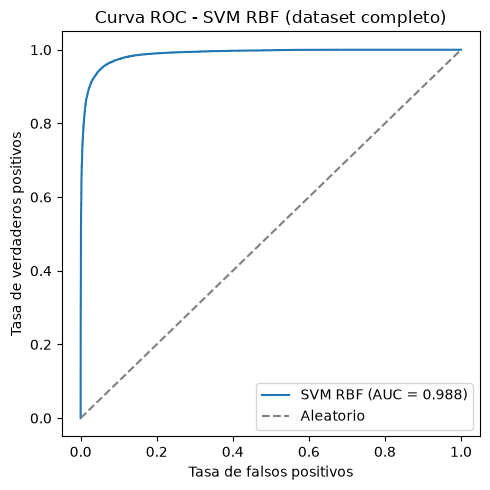

In [11]:
cm = confusion_matrix(y_test, y_pred_rbf)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("Matriz de confusión - SVM RBF (dataset completo)")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "svm_rbf_matriz_confusion.png"), dpi=DPI, bbox_inches="tight")
plt.show()

fpr, tpr, _ = roc_curve(y_test, punt_rbf)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f"SVM RBF (AUC = {met_rbf_test['auc']:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Aleatorio")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curva ROC - SVM RBF (dataset completo)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "svm_rbf_roc.png"), dpi=DPI, bbox_inches="tight")
plt.show()

## 5. Comprobación secundaria: SVC con RBF exacto sobre un submuestreo

In [12]:
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=N_SUB,
                                      stratify=y_train, random_state=RANDOM_STATE)
print("Submuestreo:", X_sub.shape, "| clases:", np.unique(y_sub, return_counts=True))

res_svc = []
for Cval in [0.1, 1, 10]:
    t0 = time.time()
    svc = SVC(kernel="rbf", gamma=GAMMA_BEST, C=Cval, cache_size=2000)
    svc.fit(X_sub, y_sub)
    t_fit = time.time() - t0
    met, _, _ = evaluar(svc, X_val, y_val)
    res_svc.append({"C": Cval, "acc_val": met["acc"], "f1_macro_val": met["f1_macro"],
                    "n_vectores_soporte": int(svc.n_support_.sum()), "seg": t_fit})
    print(res_svc[-1])

df_svc = pd.DataFrame(res_svc)
C_SVC = float(df_svc.sort_values(["f1_macro_val", "acc_val"], ascending=False).iloc[0]["C"])
print("Mejor C para SVC exacto:", C_SVC)
df_svc

Submuestreo: (30000, 30) | clases: (array([0, 1]), array([16947, 13053]))
{'C': 0.1, 'acc_val': 0.9248027666702691, 'f1_macro_val': 0.9238637472703647, 'n_vectores_soporte': 6043, 'seg': 13.184334516525269}
{'C': 1, 'acc_val': 0.9304874094888145, 'f1_macro_val': 0.9294489527323995, 'n_vectores_soporte': 4206, 'seg': 9.964005708694458}
{'C': 10, 'acc_val': 0.9298605857559711, 'f1_macro_val': 0.9286801810172873, 'n_vectores_soporte': 3404, 'seg': 9.278733015060425}
Mejor C para SVC exacto: 1.0


,C,acc_val,f1_macro_val,n_vectores_soporte,seg
0,0.1,0.924803,0.923864,6043,13.184335
1,1.0,0.930487,0.929449,4206,9.964006
2,10.0,0.929861,0.928680,3404,9.278733


In [13]:
# SVC exacto final sobre el submuestreo
t0 = time.time()
svc_final = SVC(kernel="rbf", gamma=GAMMA_BEST, C=C_SVC, cache_size=2000).fit(X_sub, y_sub)
t_fit_svc = time.time() - t0
met_svc_test, _, _ = evaluar(svc_final, X_test, y_test)
met_svc_test["t_ajuste_s"] = t_fit_svc

# Nystroem con la configuración elegida, sobre el mismo submuestreo
t0 = time.time()
nys_sub = make_pipeline(
    Nystroem(kernel="rbf", gamma=GAMMA_BEST, n_components=N_COMPONENTS, random_state=RANDOM_STATE),
    LinearSVC(C=C_BEST, dual=False, max_iter=5000, random_state=RANDOM_STATE),
).fit(X_sub, y_sub)
t_fit_nys_sub = time.time() - t0
met_nys_sub_test, _, _ = evaluar(nys_sub, X_test, y_test)
met_nys_sub_test["t_ajuste_s"] = t_fit_nys_sub

print("SVC exacto (submuestreo):", {k: round(v, 4) for k, v in met_svc_test.items()})
print("Nystroem   (submuestreo):", {k: round(v, 4) for k, v in met_nys_sub_test.items()})

SVC exacto (submuestreo): {'acc': 0.938, 'f1_macro': 0.9374, 'auc': 0.9843, 'sens_vigilia': np.float64(0.9222), 'sens_sueno': np.float64(0.9584), 't_inferencia_s': 16.7989, 't_ajuste_s': 9.8198}
Nystroem   (submuestreo): {'acc': 0.9405, 'f1_macro': 0.9399, 'auc': 0.9864, 'sens_vigilia': np.float64(0.926), 'sens_sueno': np.float64(0.9591), 't_inferencia_s': 1.0551, 't_ajuste_s': 5.7149}


## 6. Resumen en test

In [14]:
filas = [
    ("SVM lineal (train completo)", met_lineal_test, len(y_train)),
    ("SVM RBF Nystroem (train completo)", met_rbf_test, len(y_train)),
    (f"SVM RBF Nystroem (submuestreo {N_SUB})", met_nys_sub_test, N_SUB),
    (f"SVM RBF exacto (submuestreo {N_SUB})", met_svc_test, N_SUB),
]
resumen = pd.DataFrame([{"Modelo": n, "Épocas train": m_train, **met} for n, met, m_train in filas])
resumen = resumen[["Modelo", "Épocas train", "acc", "f1_macro", "auc",
                   "sens_vigilia", "sens_sueno", "t_ajuste_s", "t_inferencia_s"]]
resumen.to_csv(RESULTS_CSV, index=False)

with open(os.path.join(DATA_DIR, "svm_rbf_hiperparametros.json"), "w") as f:
    json.dump({"gamma": GAMMA_BEST, "C_nystroem": C_BEST, "C_svc_exacto": C_SVC,
               "n_components": N_COMPONENTS, "n_sub": N_SUB}, f, indent=2)

resumen.round(4)

,Modelo,Épocas train,acc,f1_macro,auc,sens_vigilia,sens_sueno,t_ajuste_s,t_inferencia_s
0,SVM lineal (train completo),205045,0.9186,0.9179,0.9752,0.8964,0.9470,1.4080,0.0573
1,SVM RBF Nystroem (train completo),205045,0.9436,0.9430,0.9884,0.9305,0.9604,55.4031,1.0053
2,SVM RBF Nystroem (submuestreo 30000),30000,0.9405,0.9399,0.9864,0.9260,0.9591,5.7149,1.0551
3,SVM RBF exacto (submuestreo 30000),30000,0.9380,0.9374,0.9843,0.9222,0.9584,9.8198,16.7989
